# Câu e. Phân cụm và đánh giá kết quả

**Thuật toán:** K-Means (`n_init = 10`, `random_state = 2476`). Lý do: (i) câu d chuẩn bị dữ liệu cho khoảng cách Euclid; (ii) tâm cụm là trung bình nên mô tả cụm trực tiếp được; (iii) K-Means nhạy với thang đo và ngoại lai, nên làm lộ rõ tác dụng của tiền xử lý, đúng điều cần so sánh.

**Hai kịch bản**

| | Trước xử lý | Sau xử lý |
|---|---|---|
| Dữ liệu | `customers_dirty.csv` | `customers_prepared.csv` |
| Biến đổi | Tối thiểu để thuật toán chạy được: điền median/mode cho ô thiếu, one-hot thuộc tính danh mục. Không log, không chuẩn hóa, không sửa ngoại lai | Toàn bộ câu c và d |
| Số đối tượng | 220 | 220 (cùng `customer_id`) |
| Không gian đặc trưng | 9 thuộc tính số thang gốc + 14 cột one-hot | 5 thành phần chính |

**Chọn k:** mỗi kịch bản tự chọn k có silhouette cao nhất với k = 2..8, không dùng nhãn. Kèm kết quả ở k = 4 (số phân khúc thiết kế) để có phép so sánh cùng k.

**Chỉ số:** không gian đặc trưng của hai kịch bản khác nhau nên silhouette và Davies–Bouldin tính trong từng không gian **không so sánh trực tiếp được**. So sánh công bằng dùng: (1) **ARI, NMI** so với `true_segment` (không phụ thuộc không gian đặc trưng; chỉ số chính); (2) silhouette của cả hai bộ nhãn tính trên **cùng một không gian tham chiếu** (8 thuộc tính số đã log và chuẩn hóa). `true_segment` chỉ được dùng ở câu này và chỉ để đánh giá.

In [1]:
import sys, warnings
sys.path.append("../src")
from utils import *
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, davies_bouldin_score, adjusted_rand_score,
                             normalized_mutual_info_score)
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220, "display.max_columns", 30)
sns.set_theme(style="whitegrid", font_scale=0.9)
OUT_FIG = ROOT / "outputs" / "figures"; OUT_TAB = ROOT / "outputs" / "tables"
OUT_FIG.mkdir(parents=True, exist_ok=True); OUT_TAB.mkdir(parents=True, exist_ok=True)

dirty = load_raw("customers_dirty")
pre = pd.read_csv(PROCESSED / "customers_preprocessed.csv")
prepared = pd.read_csv(PROCESSED / "customers_prepared.csv")
ref = pd.read_csv(PROCESSED / "customers_scaled_numeric.csv")
assert (dirty[ID_COL] == prepared[ID_COL]).all() and (dirty[ID_COL] == ref[ID_COL]).all()

# Kich ban truoc xu ly: bien doi toi thieu
Xb = dirty[INPUT_COLS].copy()
for c in NUM_COLS: Xb[c] = Xb[c].astype(float).fillna(Xb[c].median())
Xb["preferred_category"] = Xb.preferred_category.fillna(Xb.preferred_category.mode()[0])
Xb = pd.get_dummies(Xb, columns=["gender", "region", "membership_tier", "preferred_category"]).astype(float)
Xa = prepared.drop(columns=ID_COL)
Xref = ref.drop(columns=ID_COL).to_numpy()
SPACES = {"Trước xử lý": Xb.to_numpy(), "Sau xử lý": Xa.to_numpy()}
print({k: v.shape for k, v in SPACES.items()})
var_share = (Xb.var() / Xb.var().sum()).sort_values(ascending=False)
print("Ti trong phuong sai trong khong gian truoc xu ly:"); print(var_share.head(4).round(4))

{'Trước xử lý': (220, 23), 'Sau xử lý': (220, 5)}
Ti trong phuong sai trong khong gian truoc xu ly:
avg_order_value             0.9822
annual_income               0.0167
days_since_last_purchase    0.0006
sessions_per_month          0.0003
dtype: float64


## E1. Chọn k

k do silhouette chon: {'Sau xử lý': 3, 'Trước xử lý': 2}


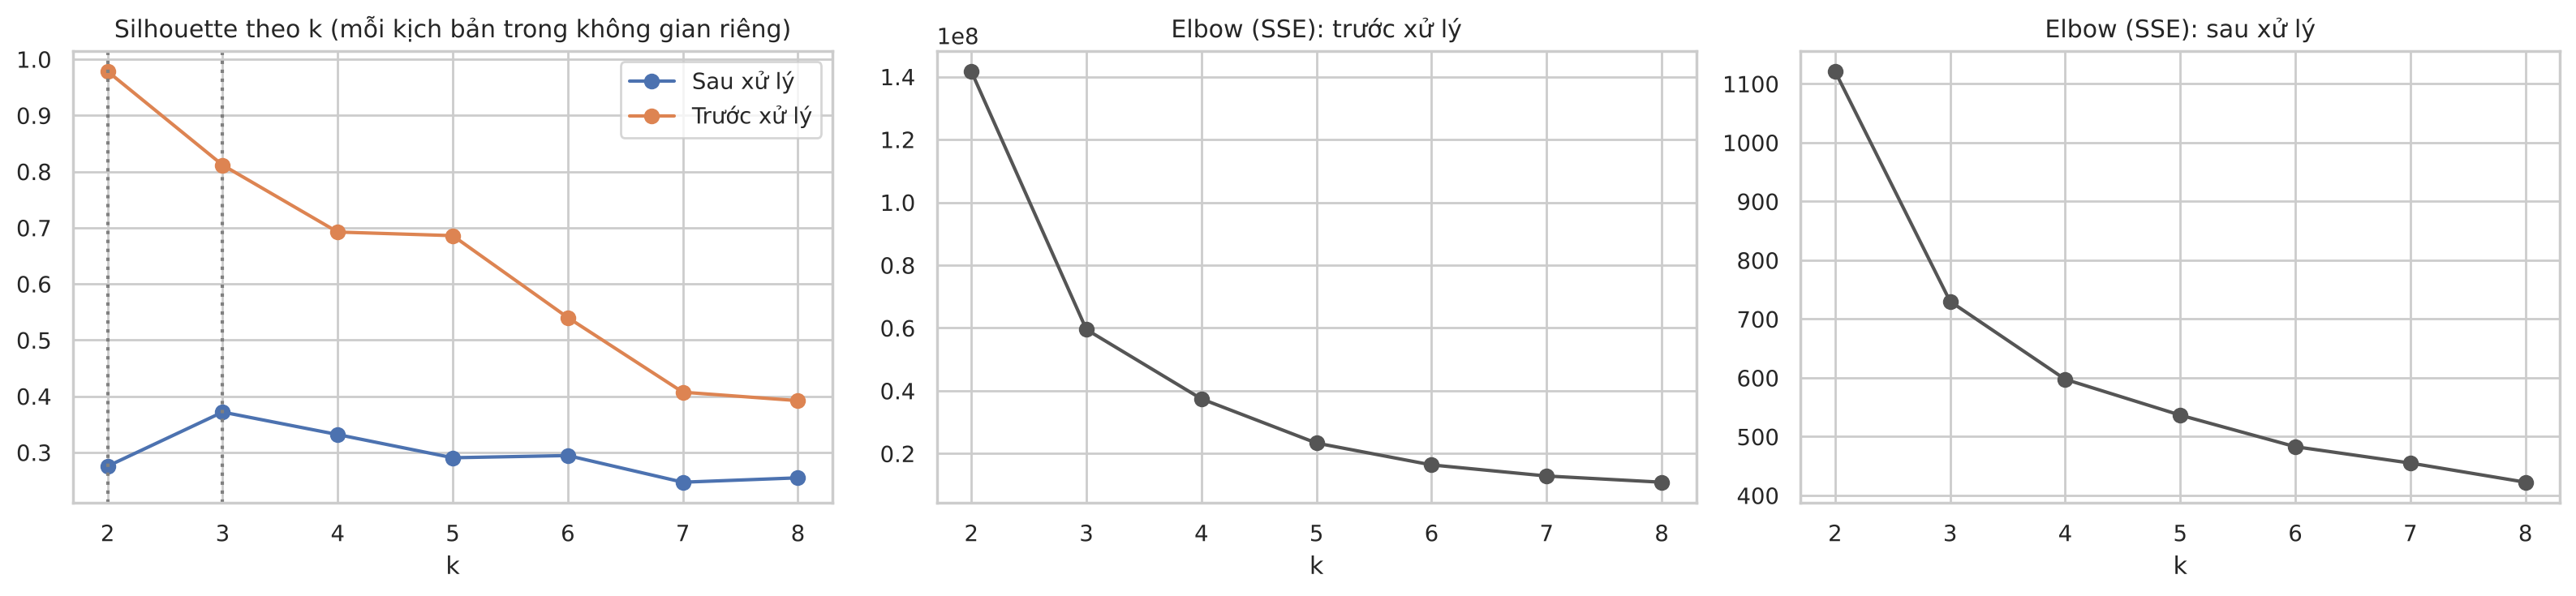

,kich_ban,k,SSE,silhouette,davies_bouldin,kich_thuoc_cum
0,Trước xử lý,2,1.417100e+08,0.978,0.077,"[217, 3]"
1,Trước xử lý,3,5.951184e+07,0.812,0.352,"[205, 12, 3]"
2,Trước xử lý,4,3.742804e+07,0.692,0.421,"[183, 29, 5, 3]"
3,Trước xử lý,5,2.334988e+07,0.686,0.396,"[183, 29, 5, 2, 1]"
4,Trước xử lý,6,1.639836e+07,0.540,0.483,"[163, 37, 12, 5, 2, 1]"
5,Trước xử lý,7,1.286625e+07,0.407,0.569,"[119, 64, 22, 8, 4, 2, 1]"
6,Trước xử lý,8,1.088965e+07,0.392,0.601,"[114, 66, 20, 10, 4, 3, 2, 1]"
7,Sau xử lý,2,1.121145e+03,0.275,1.379,"[139, 81]"
8,Sau xử lý,3,7.299530e+02,0.372,1.007,"[86, 74, 60]"
9,Sau xử lý,4,5.974970e+02,0.332,1.133,"[69, 63, 59, 29]"


In [2]:
KS = range(2, 9); rows = []; MODELS = {}
for name, V in SPACES.items():
    for k in KS:
        km = KMeans(k, n_init=10, random_state=SEED).fit(V); MODELS[name, k] = km.labels_
        rows.append({"kich_ban": name, "k": k, "SSE": km.inertia_, "silhouette": silhouette_score(V, km.labels_),
                     "davies_bouldin": davies_bouldin_score(V, km.labels_),
                     "kich_thuoc_cum": sorted(np.bincount(km.labels_).tolist(), reverse=True)})
ksel = pd.DataFrame(rows)
BEST_K = ksel.loc[ksel.groupby("kich_ban").silhouette.idxmax()].set_index("kich_ban").k.to_dict()
print("k do silhouette chon:", BEST_K)
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for name, g in ksel.groupby("kich_ban"):
    axes[0].plot(g.k, g.silhouette, "o-", label=name); axes[0].axvline(BEST_K[name], ls=":", color="gray")
    axes[1 if name == "Trước xử lý" else 2].plot(g.k, g.SSE, "o-", color="#555555")
axes[0].set_title("Silhouette theo k (mỗi kịch bản trong không gian riêng)"); axes[0].legend()
axes[1].set_title("Elbow (SSE): trước xử lý"); axes[2].set_title("Elbow (SSE): sau xử lý")
for ax in axes: ax.set_xlabel("k")
fig.tight_layout(); fig.savefig(OUT_FIG / "e_choose_k.png", dpi=150); plt.show()
ksel.to_csv(OUT_TAB / "e_k_selection.csv", index=False, encoding="utf-8-sig")
ksel.round(3)

**Nhận xét E1.**

- **Trước xử lý, silhouette chọn k = 2 với giá trị 0,978, nhưng đây là kết quả vô nghĩa:** hai cụm có 217 và 3 khách. Lý do: không chuẩn hóa nên `avg_order_value` chiếm 98,2% tổng phương sai và `annual_income` 1,7%; 21 cột còn lại gần như không tham gia vào khoảng cách. K-Means chỉ tách 3 khách có AOV khoảng 30.000–36.000 khỏi phần còn lại. Tăng k chỉ tách thêm các cụm 1–5 khách. Đây là ví dụ rõ rằng **silhouette cao không đồng nghĩa với phân cụm tốt**: cô lập vài điểm cực trị luôn cho silhouette rất cao.
- **Sau xử lý, silhouette chọn k = 3** (0,372), tiếp theo là k = 4 (0,332). Các cụm cân đối (86, 74, 60). Đường elbow không có điểm gãy rõ giữa k = 3 và k = 4.

## E2. So sánh hai kịch bản

In [3]:
clean = load_raw("customers_clean"); log = load_raw("injection_log")
truth = clean.true_segment
kind = dirty[ID_COL].map(log[log.kind.str.startswith("outlier")].drop_duplicates(ID_COL).set_index(ID_COL).kind).fillna("binh_thuong")
no_valid = (kind != "outlier_valid").to_numpy()

def evaluate(scen, k, labels, V):
    n = np.bincount(labels)
    return {"kich_ban": scen, "k": k, "ARI": adjusted_rand_score(truth, labels), "NMI": normalized_mutual_info_score(truth, labels),
            "ARI_bo_7_cuc_tri_hop_le": adjusted_rand_score(truth[no_valid], labels[no_valid]),
            "silhouette_khong_gian_rieng": silhouette_score(V, labels),
            "silhouette_khong_gian_tham_chieu": silhouette_score(Xref, labels),
            "davies_bouldin_rieng": davies_bouldin_score(V, labels),
            "cum_nho_nhat": n.min(), "cum_nho_nhat_%": 100 * n.min() / len(labels), "kich_thuoc_cum": sorted(n.tolist(), reverse=True)}
rows = []
for name, V in SPACES.items():
    for k in sorted({BEST_K[name], 4}):
        r = evaluate(name, k, MODELS[name, k], V); r["k_do_silhouette_chon"] = (k == BEST_K[name]); rows.append(r)
cmp_ = pd.DataFrame(rows); cmp_.to_csv(OUT_TAB / "e_comparison.csv", index=False, encoding="utf-8-sig")
LB, LA = MODELS["Trước xử lý", BEST_K["Trước xử lý"]], MODELS["Sau xử lý", BEST_K["Sau xử lý"]]
print("Muc do giong nhau giua hai bo nhan (ARI truoc so voi sau):", round(adjusted_rand_score(LB, LA), 3),
      "| o k = 4:", round(adjusted_rand_score(MODELS["Trước xử lý", 4], MODELS["Sau xử lý", 4]), 3))
cmp_.round(3)

Muc do giong nhau giua hai bo nhan (ARI truoc so voi sau): -0.004 | o k = 4: 0.173


,kich_ban,k,ARI,NMI,ARI_bo_7_cuc_tri_hop_le,silhouette_khong_gian_rieng,silhouette_khong_gian_tham_chieu,davies_bouldin_rieng,cum_nho_nhat,cum_nho_nhat_%,kich_thuoc_cum,k_do_silhouette_chon
0,Trước xử lý,2,0.011,0.039,0.000,0.978,0.494,0.077,3,1.364,"[217, 3]",True
1,Trước xử lý,4,0.179,0.367,0.160,0.692,0.181,0.421,3,1.364,"[183, 29, 5, 3]",False
2,Sau xử lý,3,0.751,0.792,0.776,0.372,0.327,1.007,60,27.273,"[86, 74, 60]",True
3,Sau xử lý,4,0.864,0.829,0.862,0.332,0.286,1.133,29,13.182,"[69, 63, 59, 29]",False


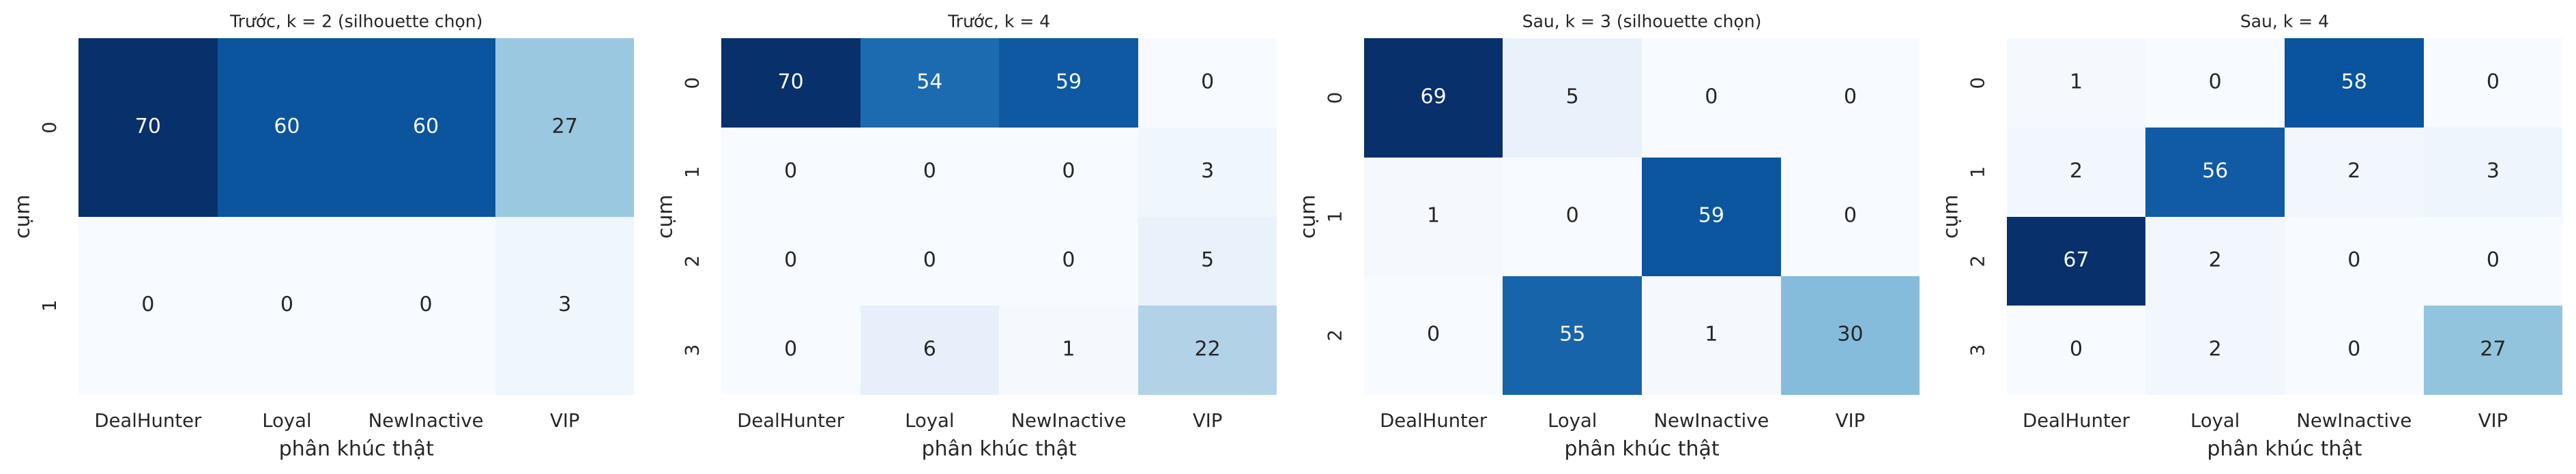

Loai ngoai lai da cai x cum:
              Trước    Sau         Sau k=4            
col_0             0  1   0   1   2       0   1   2   3
customer_id                                           
binh_thuong     205  0  72  56  77      55  61  67  22
outlier_error     5  0   1   2   2       2   2   1   0
outlier_logic     3  0   1   2   0       2   0   1   0
outlier_valid     4  3   0   0   7       0   0   0   7


In [4]:
def xt(labels): return pd.crosstab(pd.Series(labels, name="cụm"), truth.rename("phân khúc thật"))
fig, axes = plt.subplots(1, 4, figsize=(19, 3.6))
for ax, (t, lab) in zip(axes, [(f"Trước, k = {BEST_K['Trước xử lý']} (silhouette chọn)", LB), ("Trước, k = 4", MODELS["Trước xử lý", 4]),
                               (f"Sau, k = {BEST_K['Sau xử lý']} (silhouette chọn)", LA), ("Sau, k = 4", MODELS["Sau xử lý", 4])]):
    sns.heatmap(xt(lab), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax); ax.set_title(t, fontsize=9)
fig.tight_layout(); fig.savefig(OUT_FIG / "e_crosstab.png", dpi=150); plt.show()
print("Loai ngoai lai da cai x cum:")
print(pd.concat({"Trước": pd.crosstab(kind, LB), "Sau": pd.crosstab(kind, LA), "Sau k=4": pd.crosstab(kind, MODELS["Sau xử lý", 4])}, axis=1))

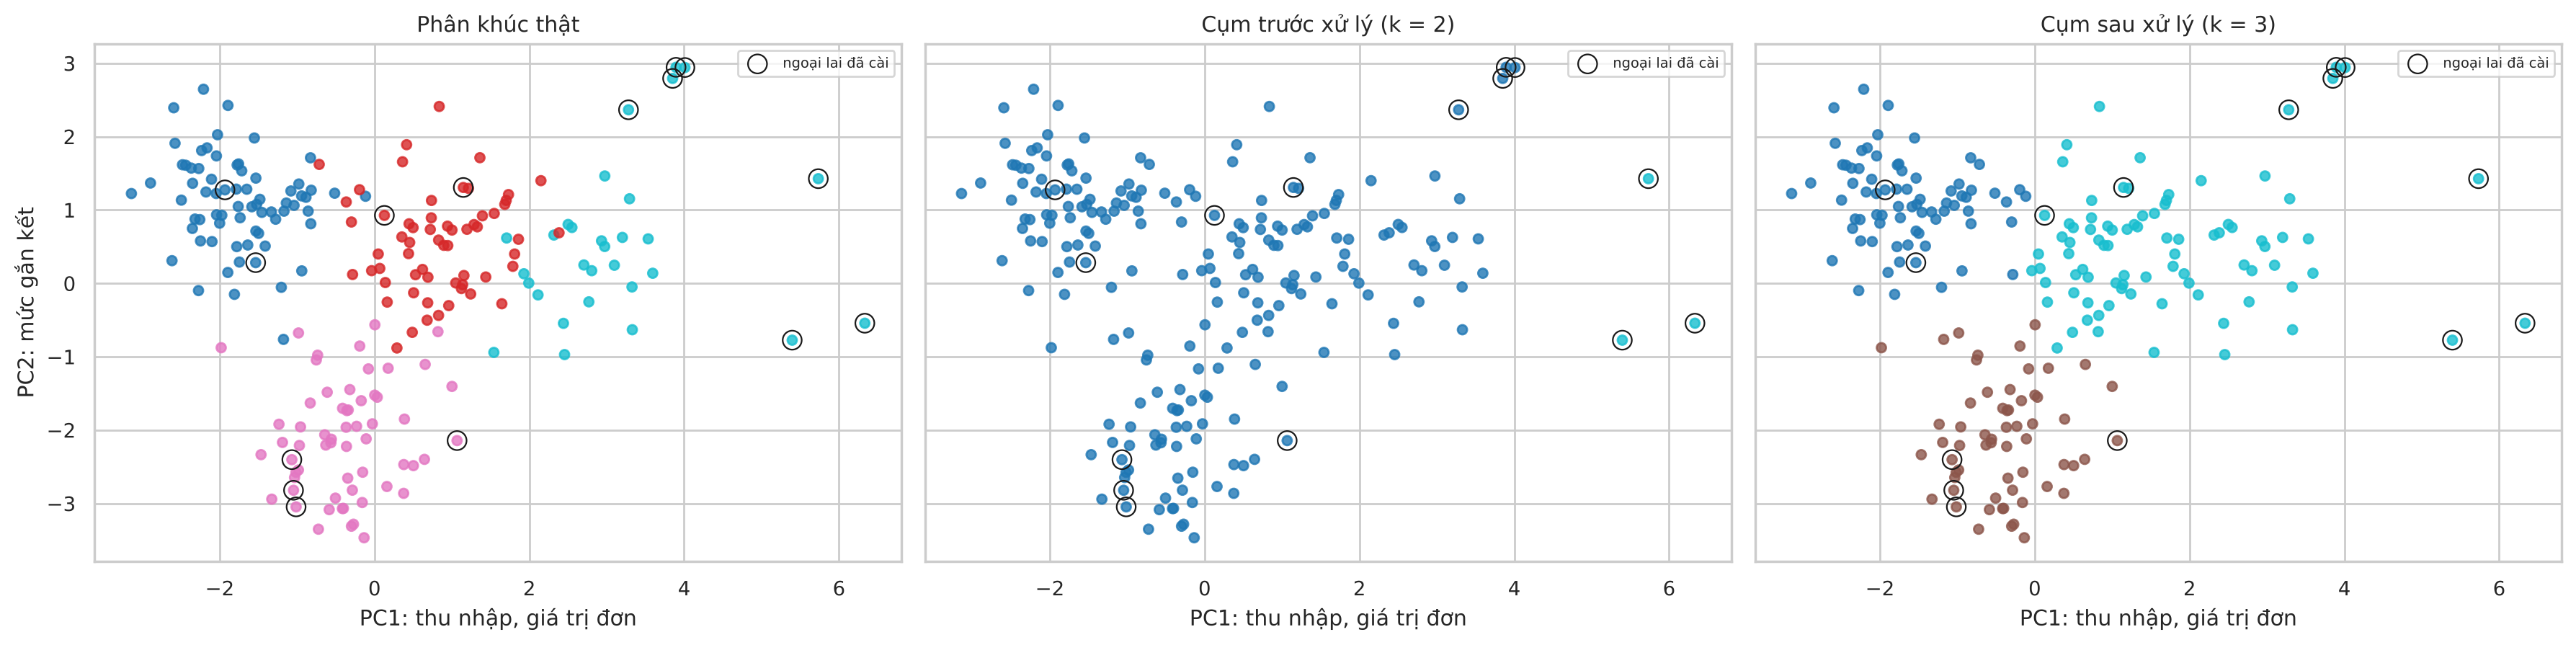

In [5]:
# Hinh chieu len mat phang PC1-PC2 cua du lieu da chuan bi (cung toa do cho ca hai bo nhan)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6), sharex=True, sharey=True)
for ax, (t, lab) in zip(axes, [("Phân khúc thật", truth.astype("category").cat.codes.to_numpy()),
                               (f"Cụm trước xử lý (k = {BEST_K['Trước xử lý']})", LB), (f"Cụm sau xử lý (k = {BEST_K['Sau xử lý']})", LA)]):
    ax.scatter(Xa.PC1, Xa.PC2, c=lab, cmap="tab10", s=22, alpha=.8)
    o = (kind != "binh_thuong").to_numpy()
    ax.scatter(Xa.PC1[o], Xa.PC2[o], s=90, facecolors="none", edgecolors="k", lw=.8, label="ngoại lai đã cài")
    ax.set_title(t); ax.set_xlabel("PC1: thu nhập, giá trị đơn"); ax.legend(fontsize=7)
axes[0].set_ylabel("PC2: mức gắn kết"); fig.tight_layout(); fig.savefig(OUT_FIG / "e_clusters_2d.png", dpi=150); plt.show()

**Nhận xét E2.**

| Chỉ số (k do silhouette chọn) | Trước xử lý (k = 2) | Sau xử lý (k = 3) |
|---|---|---|
| ARI với phân khúc thật | 0,011 | **0,751** |
| NMI | 0,039 | **0,792** |
| Cụm nhỏ nhất | 3 khách (1,4%) | 60 khách (27,3%) |
| Silhouette (không gian riêng) | 0,978 | 0,372 |
| Silhouette (cùng không gian tham chiếu) | 0,494 | 0,327 |

- **Kết quả thay đổi hoàn toàn:** ARI giữa hai bộ nhãn trước và sau là −0,004, tức hai cách phân cụm không liên quan gì đến nhau. Trước xử lý, phân cụm gần như ngẫu nhiên so với cấu trúc thật (ARI 0,011); sau xử lý đạt 0,751.
- **Ở cùng k = 4**, kết luận giữ nguyên: ARI 0,179 (trước) so với 0,864 (sau). Trước xử lý, k = 4 cho các cụm 183, 29, 5, 3: một cụm khổng lồ gộp gần hết khách, và các cụm nhỏ chia theo mức AOV.
- **Số phận các ngoại lai:** trước xử lý, 3 khách siêu VIP tạo riêng một cụm (ở k = 4 có thêm cụm 5 khách chứa 4 khách sỉ), tức ngoại lai hợp lệ quyết định toàn bộ cấu trúc. Sau xử lý, cả 7 khách cực trị hợp lệ nằm trong cụm giá trị cao (cùng các khách VIP khác), và 8 dòng lỗi đã sửa phân tán vào các cụm như khách bình thường. Việc giữ lại cực trị hợp lệ ở câu c không gây hại: ARI khi tính và không tính 7 dòng này gần như nhau (0,751 và 0,776).
- **Cảnh báo về silhouette:** ngay cả khi tính trên cùng một không gian tham chiếu, bộ nhãn trước xử lý (217 và 3) vẫn có silhouette cao hơn (0,494 so với 0,327). Silhouette thưởng cho việc cô lập vài điểm xa, nên **không thể dùng silhouette để kết luận kịch bản nào tốt hơn**; kết luận phải dựa trên ARI/NMI, kích thước cụm và khả năng diễn giải.
- **Silhouette chọn thiếu một cụm.** Dữ liệu có 4 phân khúc nhưng k = 3 gộp VIP vào cùng cụm với Loyal (xem bảng chéo). k = 4 tách được VIP (29 khách, 93% đúng) và đạt ARI 0,864. Đây đúng là rủi ro đã nêu trước khi chạy: VIP chỉ có 30 khách và nằm sát Loyal trên trục gắn kết, nên tách ra làm giảm silhouette trung bình dù đúng về cấu trúc.

## E3. Đặc điểm các cụm

In [6]:
def profile(labels, src):
    g = src.groupby(labels)
    p = g[NUM_COLS].median().round(2); p.insert(0, "n", g.size()); p.insert(1, "%", (100 * g.size() / len(src)).round(1))
    p["tier_pho_bien"] = g.membership_tier.agg(lambda s: s.mode()[0])
    p["category_pho_bien"] = g.preferred_category.agg(lambda s: f"{s.mode()[0]} ({(s == s.mode()[0]).mean():.0%})")
    p["nu_%"] = (100 * g.gender.apply(lambda s: (s == "Nữ").mean())).round(0)
    p["phan_khuc_that_chinh"] = pd.Series(truth.to_numpy()).groupby(labels).agg(lambda s: f"{s.mode()[0]} ({(s == s.mode()[0]).mean():.0%})")
    return p
prof_after = profile(LA, pre); prof_after.to_csv(OUT_TAB / "e_cluster_profile_after.csv", encoding="utf-8-sig")
print(f"SAU XU LY (k = {BEST_K['Sau xử lý']}), median tren thang goc:")
prof_after.T

SAU XU LY (k = 3), median tren thang goc:


,0,1,2
n,74,60,86
%,33.6,27.3,39.1
age,25.5,29.0,39.0
tenure_months,22.0,3.0,51.0
annual_income,146.15,186.35,360.75
orders_per_year,43.0,3.0,23.5
avg_order_value,231.0,395.7,746.95
days_since_last_purchase,5.0,122.5,14.0
return_rate,0.18,0.08,0.08
discount_usage_rate,0.72,0.3,0.32


In [7]:
print("SAU XU LY, k = 4:"); prof4 = profile(MODELS["Sau xử lý", 4], pre); prof4.to_csv(OUT_TAB / "e_cluster_profile_after_k4.csv", encoding="utf-8-sig")
print(prof4.T)
filled = dirty.copy()
for c in NUM_COLS: filled[c] = filled[c].astype(float).fillna(filled[c].median())
filled["preferred_category"] = filled.preferred_category.fillna(filled.preferred_category.mode()[0])
prof_before = profile(LB, filled); prof_before.to_csv(OUT_TAB / "e_cluster_profile_before.csv", encoding="utf-8-sig")
print(f"\nTRUOC XU LY (k = {BEST_K['Trước xử lý']}):"); print(prof_before.T)
print("\nTRUOC XU LY, k = 4:"); print(profile(MODELS["Trước xử lý", 4], filled)[["n", "annual_income", "avg_order_value", "orders_per_year", "sessions_per_month", "phan_khuc_that_chinh"]])

SAU XU LY, k = 4:
                                          0                1                 2              3
n                                        59               63                69             29
%                                      26.8             28.6              31.4           13.2
age                                    29.0             37.0              25.0           42.0
tenure_months                           3.0             53.0              22.0           37.0
annual_income                         189.7            272.4             146.4          663.5
orders_per_year                         3.0             22.0              44.0           31.0
avg_order_value                       399.1            532.0             226.9         2012.7
days_since_last_purchase              127.0             20.0               5.0           10.0
return_rate                            0.08              0.1              0.18           0.05
discount_usage_rate                     0.

In [8]:
# Lien he giua cum va cac thuoc tinh danh muc da loai khoi khong gian phan cum (kiem dinh chi binh phuong)
from scipy import stats
rows = []
for c in ["gender", "region", "preferred_category", "membership_tier"]:
    chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(LA, pre[c])); rows.append({"thuoc_tinh": c, "chi2": chi2, "df": dof, "p": p})
pd.DataFrame(rows).round(4)

,thuoc_tinh,chi2,df,p
0,gender,0.4780,2,0.7874
1,region,7.1862,4,0.1264
2,preferred_category,44.2324,8,0.0000
3,membership_tier,154.4429,6,0.0000


**Nhận xét E3: đặc điểm các cụm sau xử lý (k = 3, median trên thang gốc).**

| Cụm | Quy mô | Đặc điểm | Tên gọi | Gợi ý hành động |
|---|---|---|---|---|
| 0 | 74 (33,6%) | Trẻ (25,5 tuổi), 43 đơn/năm, giá trị đơn thấp (231), dùng khuyến mãi 72% số đơn, tỷ lệ hoàn 18%, mua 5 ngày trước | **Săn khuyến mãi, mua thường xuyên** | Voucher theo ngưỡng giỏ hàng để nâng giá trị đơn; kiểm soát chi phí hoàn hàng |
| 1 | 60 (27,3%) | Gắn bó 3 tháng, 3 đơn/năm, 122 ngày chưa mua, 6 phiên/tháng | **Khách mới hoặc ít hoạt động** | Chương trình kích hoạt lại, ưu đãi đơn thứ hai, nhắc qua thông báo |
| 2 | 86 (39,1%) | 39 tuổi, gắn bó 51 tháng, thu nhập 361, giá trị đơn 747, ít dùng khuyến mãi (32%), hoàn 8% | **Trung thành, giá trị cao** | Chăm sóc ưu tiên, quyền lợi theo hạng, bán chéo |

Với **k = 4**, cụm 2 tách thành hai nhóm mà kinh doanh nên phân biệt: **Trung thành tầm trung** (63 khách; thu nhập 272, giá trị đơn 532, gắn bó 53 tháng) và **VIP** (29 khách, 13,2%; thu nhập 664, giá trị đơn 2.013, hạng Platinum, 59% ưa Điện tử, ít dùng khuyến mãi nhất 19%). Giá trị đơn của nhóm VIP gấp gần 4 lần nhóm trung thành, nên về mặt nghiệp vụ **k = 4 hữu ích hơn** dù silhouette thấp hơn.

**Thuộc tính danh mục (đã loại khỏi không gian phân cụm):** `gender` (p = 0,79) và `region` (p = 0,13) không liên hệ với cụm, xác nhận việc loại chúng. `membership_tier` liên hệ rất mạnh (đúng vì trùng thông tin với chi tiêu). `preferred_category` **có liên hệ** với cụm (p < 0,001; ví dụ VIP ưa Điện tử) dù không được dùng để phân cụm: nó hữu ích để **mô tả** cụm và cá nhân hóa gợi ý sản phẩm.

**Trước xử lý**, các cụm không diễn giải được theo hành vi: một cụm 217 khách có median trùng với median toàn bộ dữ liệu, và một cụm 3 khách siêu VIP.

## E4. Kiểm chứng các lựa chọn ở câu d và tiêu chí thành công

In [9]:
rows = []
alt = {"PCA 5 thành phần (đã chọn)": Xa.to_numpy(), "8 thuộc tính số, không PCA": Xref,
       "Không PCA + gender, region, category": np.hstack([Xref, pd.get_dummies(pre[["gender", "region", "preferred_category"]]).to_numpy(float)])}
for name, V in alt.items():
    for k in (BEST_K["Sau xử lý"], 4):
        lab = KMeans(k, n_init=10, random_state=SEED).fit_predict(V)
        rows.append({"khong_gian": name, "k": k, "ARI": adjusted_rand_score(truth, lab), "NMI": normalized_mutual_info_score(truth, lab),
                     "silhouette_rieng": silhouette_score(V, lab)})
e4 = pd.DataFrame(rows); e4.to_csv(OUT_TAB / "e_check_cau_d.csv", index=False, encoding="utf-8-sig")
print(e4.round(3))
# Do nhay voi khoi tao: 20 seed khac nhau
for name, V, k in [("Trước", SPACES["Trước xử lý"], BEST_K["Trước xử lý"]), ("Sau", SPACES["Sau xử lý"], BEST_K["Sau xử lý"]), ("Sau, k=4", SPACES["Sau xử lý"], 4)]:
    a = [adjusted_rand_score(truth, KMeans(k, n_init=10, random_state=s).fit_predict(V)) for s in range(20)]
    print(f"{name}: ARI qua 20 seed = {np.mean(a):.3f} ± {np.std(a):.3f} (min {np.min(a):.3f}, max {np.max(a):.3f})")

                             khong_gian  k    ARI    NMI  silhouette_rieng
0            PCA 5 thành phần (đã chọn)  3  0.751  0.792             0.372
1            PCA 5 thành phần (đã chọn)  4  0.864  0.829             0.332
2            8 thuộc tính số, không PCA  3  0.751  0.792             0.327
3            8 thuộc tính số, không PCA  4  0.885  0.851             0.287
4  Không PCA + gender, region, category  3  0.751  0.792             0.254
5  Không PCA + gender, region, category  4  0.889  0.854             0.214


Trước: ARI qua 20 seed = 0.011 ± 0.000 (min 0.011, max 0.011)


Sau: ARI qua 20 seed = 0.751 ± 0.000 (min 0.751, max 0.751)


Sau, k=4: ARI qua 20 seed = 0.866 ± 0.004 (min 0.864, max 0.872)


In [10]:
r = cmp_[cmp_.k_do_silhouette_chon].set_index("kich_ban")
crit = pd.DataFrame({
    "tieu_chi": ["3–6 cụm", "Cụm nhỏ nhất ≥ 5%", "ARI ≥ 0,6", "Silhouette ≥ 0,25 (không gian riêng)"],
    "Trước xử lý": [r.loc["Trước xử lý", "k"], round(r.loc["Trước xử lý", "cum_nho_nhat_%"], 1), round(r.loc["Trước xử lý", "ARI"], 3), round(r.loc["Trước xử lý", "silhouette_khong_gian_rieng"], 3)],
    "Sau xử lý": [r.loc["Sau xử lý", "k"], round(r.loc["Sau xử lý", "cum_nho_nhat_%"], 1), round(r.loc["Sau xử lý", "ARI"], 3), round(r.loc["Sau xử lý", "silhouette_khong_gian_rieng"], 3)]})
def ok(col): return [3 <= col[0] <= 6, col[1] >= 5, col[2] >= 0.6, col[3] >= 0.25]
crit["Trước đạt"] = ok(crit["Trước xử lý"].tolist()); crit["Sau đạt"] = ok(crit["Sau xử lý"].tolist())
crit.to_csv(OUT_TAB / "e_success_criteria.csv", index=False, encoding="utf-8-sig")
pd.DataFrame({ID_COL: dirty[ID_COL], "cum_truoc": LB, "cum_sau": LA, "cum_truoc_k4": MODELS["Trước xử lý", 4],
              "cum_sau_k4": MODELS["Sau xử lý", 4]}).to_csv(PROCESSED / "cluster_assignments.csv", index=False)
crit

,tieu_chi,Trước xử lý,Sau xử lý,Trước đạt,Sau đạt
0,3–6 cụm,2.000,3.000,False,True
1,Cụm nhỏ nhất ≥ 5%,1.400,27.300,False,True
2,"ARI ≥ 0,6",0.011,0.751,False,True
3,"Silhouette ≥ 0,25 (không gian riêng)",0.978,0.372,True,True


**Nhận xét E4.**

*Kiểm chứng các lựa chọn ở câu d bằng nhãn thật:*
- **PCA không giúp tìm đúng cấu trúc hơn.** Ở k = 3, ARI giống hệt nhau (0,751) cho PCA và cho 8 thuộc tính số không PCA; ở k = 4, PCA hơi kém hơn (0,864 so với 0,885). Mức cải thiện silhouette nhờ PCA ở câu d (0,372 so với 0,327) đúng là hiệu ứng của thước đo khi giảm số chiều, như đã cảnh báo. PCA vẫn có ích ở chỗ giảm từ 8 xuống 5 chiều mà gần như không mất chất lượng và cho hai trục diễn giải được.
- **Thuộc tính danh mục không làm hỏng kết quả như silhouette gợi ý.** Thêm gender, region, category làm silhouette giảm mạnh (0,287 xuống 0,214 ở k = 4) nhưng ARI gần như không đổi (0,885 và 0,889). Kết luận trung thực: việc loại chúng ở câu d là vô hại và làm mô hình gọn hơn, nhưng lý do "làm giảm chất lượng cụm" chỉ đúng theo silhouette, không đúng theo cấu trúc thật.
- Hai điểm trên cùng dẫn tới một bài học: **silhouette là tiêu chí chọn mô hình không đáng tin trên dữ liệu này**; nó chọn sai k trước xử lý (k = 2), chọn thiếu một cụm sau xử lý (k = 3), và phóng đại lợi ích của PCA.
- **Độ ổn định theo khởi tạo:** ARI qua 20 seed gần như không đổi (0,751 ± 0,000 ở k = 3; 0,866 ± 0,004 ở k = 4), nên kết quả không phụ thuộc vào seed.

*Tiêu chí thành công đặt ra ở câu a:* sau xử lý đạt cả 4 tiêu chí (3 cụm, cụm nhỏ nhất 27,3%, ARI 0,751, silhouette 0,372). Trước xử lý chỉ đạt tiêu chí silhouette, và đạt vì lý do sai.

## Tóm tắt câu e

- **Tiền xử lý và chuẩn bị dữ liệu quyết định kết quả phân cụm:** ARI từ 0,011 lên 0,751 (k do silhouette chọn), và từ 0,179 lên 0,864 ở cùng k = 4. Cụm nhỏ nhất từ 3 khách lên 60 khách.
- **Nguyên nhân chính của thất bại trước xử lý** là chênh lệch thang đo kết hợp với cực trị: một thuộc tính (AOV) chiếm 98,2% phương sai.
- **Kết quả chính theo quy trình không dùng nhãn: 3 cụm** (săn khuyến mãi; khách mới hoặc ít hoạt động; trung thành, giá trị cao). **Khuyến nghị nghiệp vụ: dùng 4 cụm**, tách riêng VIP (13%).
- **So sánh hợp lý:** cùng 220 khách, cùng thuật toán và thiết lập; không gian đặc trưng khác nhau (23 chiều thang gốc so với 5 thành phần chính) nên chỉ số nội tại không so trực tiếp; kết luận dựa trên ARI/NMI, kích thước cụm và khả năng diễn giải.

**Hạn chế:** dữ liệu giả lập có các phân khúc tách biệt hơn thực tế nên ARI lạc quan; nhãn thật chỉ có vì đây là dữ liệu sinh, trong thực tế phải dựa vào chỉ số nội tại vốn đã cho thấy kém tin cậy ở đây, nên cần thêm đánh giá của người làm nghiệp vụ; chỉ thử một thuật toán (K-Means); N = 220 nhỏ.